# Tourism Package Prediction - MLOps Project
**Visit with Us - Wellness Tourism Package**

Goal: predict whether a customer will purchase the Wellness Tourism Package *before* contacting them, and automate the whole workflow (data registration -> preparation -> model tuning with MLflow tracking -> deployment) with GitHub Actions and a Streamlit app.

| Item | Link |
|---|---|
| GitHub repository | https://github.com/jyotirmoyiitg-bit/TourismPackage |
| Streamlit Community Cloud app | https://tourismpackage-mkmancg8d7uf6xtrueratt.streamlit.app/ |

This notebook runs locally (Python 3.11 virtual environment). The scripts it displays are the same ones executed by the GitHub Actions pipeline.

## 1. Setup and Imports

In [1]:
import os, subprocess, sys, time, urllib.request
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option('display.max_columns', 30)

# Master folder layout (the notebook is run from the repository root)
for d in ["tourism_project/data", "tourism_project/model_building", "tourism_project/deployment", ".github/workflows"]:
    os.makedirs(d, exist_ok=True)
print("Working directory:", os.getcwd())
print("Python:", sys.version.split()[0])

Working directory: D:\Share\GreatLearning\MLOPs\TourisimPackage
Python: 3.11.9


## 2. Data Registration
The dataset `tourism.csv` lives in `tourism_project/data/` inside the repository (no external dataset store). `data_register.py` validates that every expected column is present and prints a summary. It exits with an error if validation fails, which stops the pipeline.

In [2]:
assert os.path.exists("tourism_project/data/tourism.csv"), "Place tourism.csv in tourism_project/data/"
print(open("tourism_project/model_building/data_register.py").read())

"""Data registration: validate the dataset stored in the repo and print a summary."""
import sys
import pandas as pd

DATA_PATH = "tourism_project/data/tourism.csv"
EXPECTED_COLUMNS = [
    "CustomerID", "ProdTaken", "Age", "TypeofContact", "CityTier", "DurationOfPitch",
    "Occupation", "Gender", "NumberOfPersonVisiting", "NumberOfFollowups",
    "ProductPitched", "PreferredPropertyStar", "MaritalStatus", "NumberOfTrips",
    "Passport", "PitchSatisfactionScore", "OwnCar", "NumberOfChildrenVisiting",
    "Designation", "MonthlyIncome",
]

df = pd.read_csv(DATA_PATH)
missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing:
    print(f"VALIDATION FAILED - missing columns: {missing}")
    sys.exit(1)

print(f"Dataset registered from {DATA_PATH}")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Extra columns (will be dropped in prep): {[c for c in df.columns if c not in EXPECTED_COLUMNS]}")
print("\nData types:\n", df.dtypes.to_string())
print("\nMis

In [3]:
!python tourism_project/model_building/data_register.py

Traceback (most recent call last):
  File "D:\Share\GreatLearning\MLOPs\TourisimPackage\tourism_project\model_building\data_register.py", line 3, in <module>
    import pandas as pd
ModuleNotFoundError: No module named 'pandas'


## 3. Exploratory Data Analysis
A quick look to justify the cleaning and modelling choices.

In [4]:
df = pd.read_csv("tourism_project/data/tourism.csv")
display(df.head())
display(df.describe().T)

,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,4128.0,2527.763808,1409.439133,0.0,1320.75,2603.5,3748.25,4887.0
CustomerID,4128.0,202527.763808,1409.439133,200000.0,201320.75,202603.5,203748.25,204887.0
ProdTaken,4128.0,0.193072,0.394757,0.0,0.00,0.0,0.00,1.0
Age,4128.0,37.231831,9.174521,18.0,31.00,36.0,43.00,61.0
CityTier,4128.0,1.663275,0.920640,1.0,1.00,1.0,3.00,3.0
DurationOfPitch,4128.0,15.584787,8.398142,5.0,9.00,14.0,20.00,127.0
NumberOfPersonVisiting,4128.0,2.949370,0.718818,1.0,2.00,3.0,3.00,5.0
NumberOfFollowups,4128.0,3.741521,1.006786,1.0,3.00,4.0,4.00,6.0
PreferredPropertyStar,4128.0,3.578488,0.795031,3.0,3.00,3.0,4.00,5.0
NumberOfTrips,4128.0,3.295300,1.856300,1.0,2.00,3.0,4.00,22.0


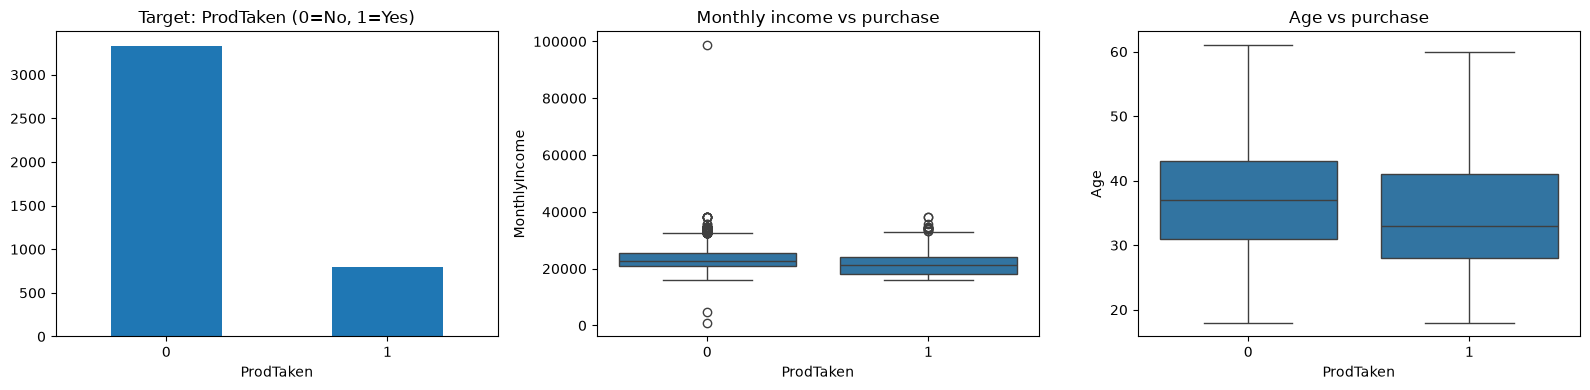

Gender
Male       2463
Female     1510
Fe Male     155
Name: count, dtype: int64 
 MaritalStatus
Married      1990
Divorced      789
Unmarried     682
Single        667
Name: count, dtype: int64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df['ProdTaken'].value_counts().plot.bar(ax=ax[0], title='Target: ProdTaken (0=No, 1=Yes)', rot=0)
sns.boxplot(data=df, x='ProdTaken', y='MonthlyIncome', ax=ax[1]); ax[1].set_title('Monthly income vs purchase')
sns.boxplot(data=df, x='ProdTaken', y='Age', ax=ax[2]); ax[2].set_title('Age vs purchase')
plt.tight_layout(); plt.show()
print(df['Gender'].value_counts(), "\n", df['MaritalStatus'].value_counts())

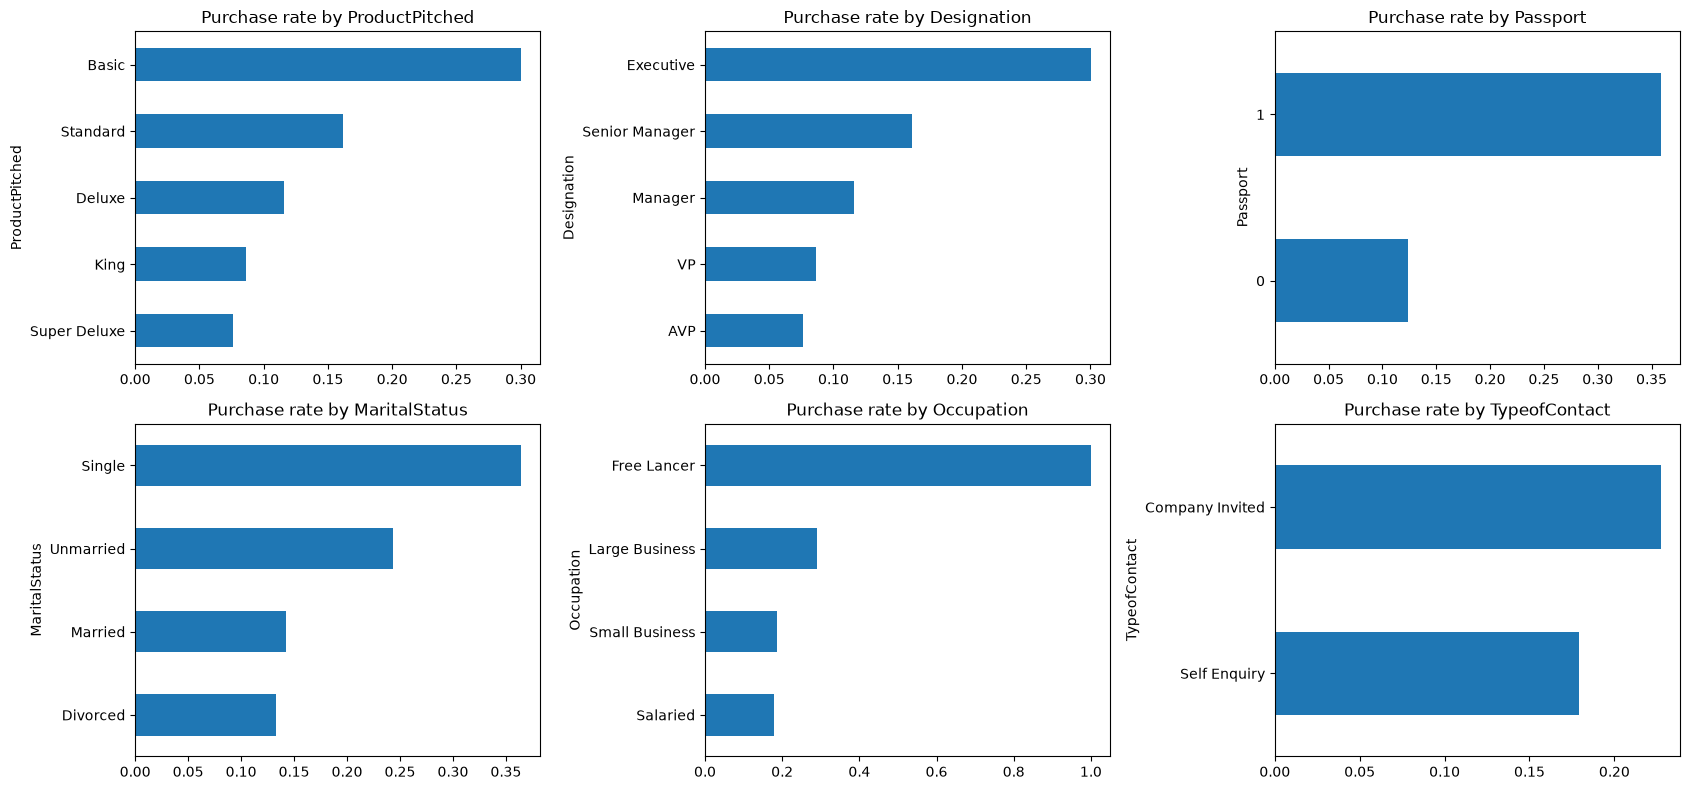

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(ax.ravel(), ['ProductPitched','Designation','Passport','MaritalStatus','Occupation','TypeofContact']):
    df.groupby(c)['ProdTaken'].mean().sort_values().plot.barh(ax=a, title=f'Purchase rate by {c}')
plt.tight_layout(); plt.show()

**Observations**
- Only ~19% of customers bought the package, so the target is imbalanced. We use stratified splitting and `scale_pos_weight` in XGBoost, and tune for recall.
- `Gender` contains an inconsistent label "Fe Male" that must be merged into "Female". `Unnamed: 0` (an index column) and `CustomerID` (an identifier) carry no predictive information and are dropped.
- Customers who hold a passport, were pitched cheaper products (Basic) or hold junior designations (Executive) buy at noticeably higher rates; income and age are also associated with purchase.
- **Caveat:** pitch-related fields (`ProductPitched`, `DurationOfPitch`, `NumberOfFollowups`, `PitchSatisfactionScore`) are only known once a salesperson has contacted the customer. They are part of the supplied data dictionary so they are used, but a strictly pre-contact model would need to exclude them.

## 4. Data Preparation
`prep.py` loads the CSV from the repository, drops unnecessary columns, fixes categories, removes duplicates, imputes any missing values, makes a stratified 80/20 train-test split and saves `Xtrain/Xtest/ytrain/ytest.csv`. In the workflow these files are passed to the training job as an artifact.

In [7]:
print(open("tourism_project/model_building/prep.py").read())

"""Data preparation: clean the dataset, split into train/test and save locally."""
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = "tourism_project/data/tourism.csv"
TARGET = "ProdTaken"

df = pd.read_csv(DATA_PATH)

# Drop the unnamed index column and the identifier - they carry no predictive signal
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed") or c == ""] + ["CustomerID"])

# Standardise inconsistent category labels
df["Gender"] = df["Gender"].replace({"Fe Male": "Female"})

# Remove duplicates and impute any missing values (median for numeric, mode for categorical)
df = df.drop_duplicates()
for col in df.columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median() if df[col].dtype != "object" else df[col].mode()[0])

X = df.drop(columns=[TARGET])
y = df[TARGET]
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Xtrain.to_csv("Xtrain.csv", index=Fa

In [8]:
!python tourism_project/model_building/prep.py

Traceback (most recent call last):
  File "D:\Share\GreatLearning\MLOPs\TourisimPackage\tourism_project\model_building\prep.py", line 2, in <module>
    import pandas as pd
ModuleNotFoundError: No module named 'pandas'


## 5. Model Training with Experiment Tracking (MLflow)
`train.py` builds a scikit-learn pipeline (StandardScaler + OneHotEncoder + XGBoost), tunes it with 5-fold `GridSearchCV` (108 combinations, scored on recall), logs **every** parameter combination and its CV score as a nested MLflow run, evaluates the best model on train and test data, and saves it to `tourism_project/deployment/`.

First start a local MLflow tracking server (UI at http://localhost:5000; no ngrok needed locally).

In [9]:
print(open("tourism_project/model_building/train.py").read())

"""Model training: tune XGBoost with GridSearchCV, track with MLflow, save the best model."""
import json
import os
import joblib
import mlflow
import pandas as pd
import xgboost as xgb
from sklearn.compose import make_column_transformer
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000"))
mlflow.set_experiment("tourism-package-prediction")

Xtrain = pd.read_csv("Xtrain.csv")
Xtest = pd.read_csv("Xtest.csv")
ytrain = pd.read_csv("ytrain.csv").squeeze()
ytest = pd.read_csv("ytest.csv").squeeze()

numeric = ["Age", "CityTier", "DurationOfPitch", "NumberOfPersonVisiting", "NumberOfFollowups",
           "PreferredPropertyStar", "NumberOfTrips", "Passport"

In [10]:
mlflow_proc = subprocess.Popen([sys.executable, "-m", "mlflow", "server", "--host", "127.0.0.1", "--port", "5000"],
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):
    try:
        urllib.request.urlopen("http://localhost:5000/health"); print("MLflow server is up at http://localhost:5000"); break
    except Exception:
        time.sleep(1)

MLflow server is up at http://localhost:5000


In [11]:
# MLflow per-trial progress lines are filtered out to keep the notebook readable
res = subprocess.run([sys.executable, "tourism_project/model_building/train.py"], capture_output=True, text=True, encoding="utf-8",
                     env={**os.environ, "PYTHONIOENCODING": "utf-8"})
print("\n".join(l for l in res.stdout.splitlines() if "View run" not in l and "View experiment" not in l))
print(res.stderr[-1500:] if res.returncode else "Training finished successfully.")

              precision    recall  f1-score   support

 No purchase       0.96      0.90      0.93       648
    Purchase       0.68      0.85      0.75       155

    accuracy                           0.89       803
   macro avg       0.82      0.87      0.84       803
weighted avg       0.91      0.89      0.90       803

{
  "train_accuracy": 0.9582,
  "train_precision": 0.8299,
  "train_recall": 0.9855,
  "train_f1": 0.901,
  "train_roc_auc": 0.9954,
  "test_accuracy": 0.8917,
  "test_precision": 0.6753,
  "test_recall": 0.8452,
  "test_f1": 0.7507,
  "test_roc_auc": 0.9328
}
Best params: {'xgbclassifier__colsample_bytree': 0.8, 'xgbclassifier__learning_rate': 0.05, 'xgbclassifier__max_depth': 7, 'xgbclassifier__n_estimators': 100, 'xgbclassifier__reg_lambda': 5}
Model saved to tourism_project/deployment/best_tourism_model.joblib
Training finished successfully.


### Tracked experiments

In [12]:
import mlflow
mlflow.set_tracking_uri("http://localhost:5000")
runs = mlflow.search_runs(experiment_names=["tourism-package-prediction"])
trials = runs[runs['tags.mlflow.runName'].fillna('').str.startswith('trial_')]
print(f"{len(runs)} runs logged ({len(trials)} tuning trials)")
cols = [c for c in trials.columns if c.startswith('params.') or c == 'metrics.mean_cv_recall']
display(trials.sort_values('metrics.mean_cv_recall', ascending=False)[cols].head(10))

109 runs logged (108 tuning trials)


,metrics.mean_cv_recall,params.reg_lambda,params.colsample_bytree,params.max_depth,params.n_estimators,params.learning_rate,params.best_learning_rate,params.best_reg_lambda,params.best_colsample_bytree,params.best_n_estimators,params.best_max_depth
40,0.786756,5,0.8,7,100,0.05,None,None,None,None,None
22,0.780370,5,0.8,7,100,0.1,None,None,None,None,None
18,0.780344,5,0.8,7,300,0.1,None,None,None,None,None
54,0.780330,5,0.6,7,300,0.2,None,None,None,None,None
23,0.780304,1,0.8,7,100,0.1,None,None,None,None,None
58,0.778718,5,0.6,7,100,0.2,None,None,None,None,None
78,0.777118,5,0.6,5,300,0.1,None,None,None,None,None
99,0.777092,1,0.6,5,200,0.05,None,None,None,None,None
97,0.777092,1,0.6,5,300,0.05,None,None,None,None,None
20,0.775505,5,0.8,7,200,0.1,None,None,None,None,None


Open http://localhost:5000 to browse the runs in the MLflow UI.

**Results:** the tuned XGBoost model reaches ~0.85 recall and ~0.93 ROC-AUC on the held-out test set (precision ~0.68, accuracy ~0.89). Recall is prioritised because missing a likely buyer costs more than contacting an unlikely one. Train metrics are higher than test (train recall ~0.99), so some overfitting remains; stronger regularisation or more data would help.

In [13]:
mlflow_proc.terminate(); print("MLflow server stopped.")

MLflow server stopped.


## 6. Model Deployment - Streamlit App
`app.py` loads the model committed by the pipeline (`tourism_project/deployment/best_tourism_model.joblib`), collects user inputs into a dataframe and displays the prediction. `tourism_project/deployment/requirements.txt` pins the versions used for training so the saved model loads identically on Streamlit Community Cloud (select **Python 3.11** in Advanced settings).

In [14]:
print(open("tourism_project/deployment/app.py").read())
print("-"*60); print(open("tourism_project/deployment/requirements.txt").read())

"""Streamlit app: predict whether a customer will purchase the Wellness Tourism Package."""
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

MODEL_PATH = Path(__file__).parent / "best_tourism_model.joblib"


@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)


artifact = load_model()
model, threshold = artifact["model"], artifact["threshold"]

st.set_page_config(page_title="Wellness Package Predictor", page_icon="ðŸ§³")
st.title("ðŸ§³ Wellness Tourism Package Predictor")
st.write("Enter the customer details to predict whether they are likely to purchase the package.")

col1, col2 = st.columns(2)
with col1:
    st.subheader("Customer details")
    age = st.number_input("Age", 18, 100, 35)
    gender = st.selectbox("Gender", ["Male", "Female"])
    marital = st.selectbox("Marital status", ["Single", "Married", "Divorced", "Unmarried"])
    occupation = st.selectbox("Occupation", ["Salaried", "Small Business", "Large Business", "Free

In [15]:
# Sanity check: load the saved model exactly as the app does and score one sample customer
import joblib
art = joblib.load("tourism_project/deployment/best_tourism_model.joblib")
sample = pd.DataFrame([{"Age": 35, "TypeofContact": "Self Enquiry", "CityTier": 1, "DurationOfPitch": 15, "Occupation": "Salaried",
    "Gender": "Male", "NumberOfPersonVisiting": 3, "NumberOfFollowups": 3, "ProductPitched": "Basic", "PreferredPropertyStar": 3.0,
    "MaritalStatus": "Single", "NumberOfTrips": 3, "Passport": 1, "PitchSatisfactionScore": 3, "OwnCar": 1,
    "NumberOfChildrenVisiting": 0, "Designation": "Executive", "MonthlyIncome": 20000}])
p = art["model"].predict_proba(sample)[0, 1]
print(f"Purchase probability: {p:.1%} -> {'Likely' if p >= art['threshold'] else 'Unlikely'} to purchase")

Purchase probability: 73.2% -> Likely to purchase


## 7. MLOps Pipeline with GitHub Actions
`.github/workflows/pipeline.yml` runs automatically on every push to `main` (and manually via *Run workflow*). It has three dependent jobs:
1. **register-dataset** - installs dependencies, runs `data_register.py`, uploads the validated dataset as an artifact.
2. **data-prep** - runs `prep.py` and uploads the train/test splits as the `data-splits` artifact.
3. **model-training** - downloads the splits, starts an MLflow server, runs `train.py`, then commits the trained model back to `main` with `[skip ci]` so the commit does not re-trigger the pipeline. The Streamlit app redeploys from that commit.

Pipeline dependencies are in `tourism_project/requirements.txt`.

In [16]:
print(open(".github/workflows/pipeline.yml").read())
print("-"*60); print(open("tourism_project/requirements.txt").read())

name: Tourism Project Pipeline

on:
  push:
    branches:
      - main
  workflow_dispatch:

permissions:
  contents: write

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Register Dataset
        run: python tourism_project/model_building/data_register.py
      - name: Upload Registered Dataset
        uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Run Data Pre

## 8. Output Evaluation
### GitHub
Repository: https://github.com/jyotirmoyiitg-bit/TourismPackage

--SCREENSHOT: repository folder structure
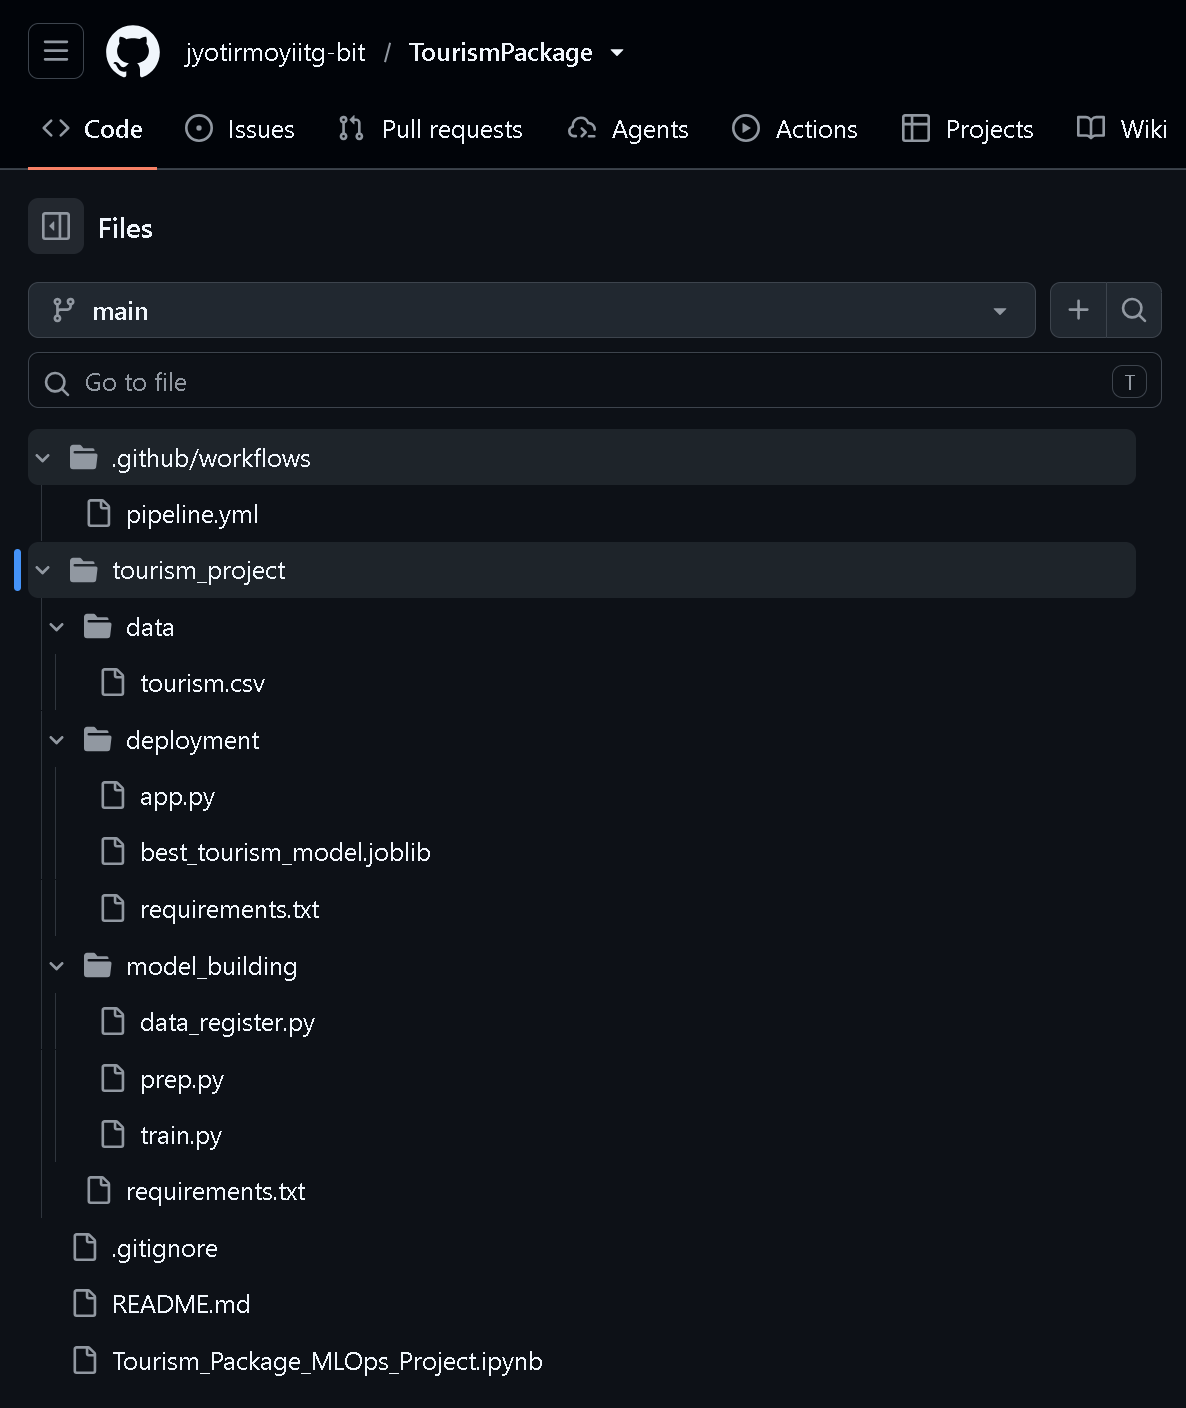

--SCREENSHOT: executed GitHub Actions workflow 
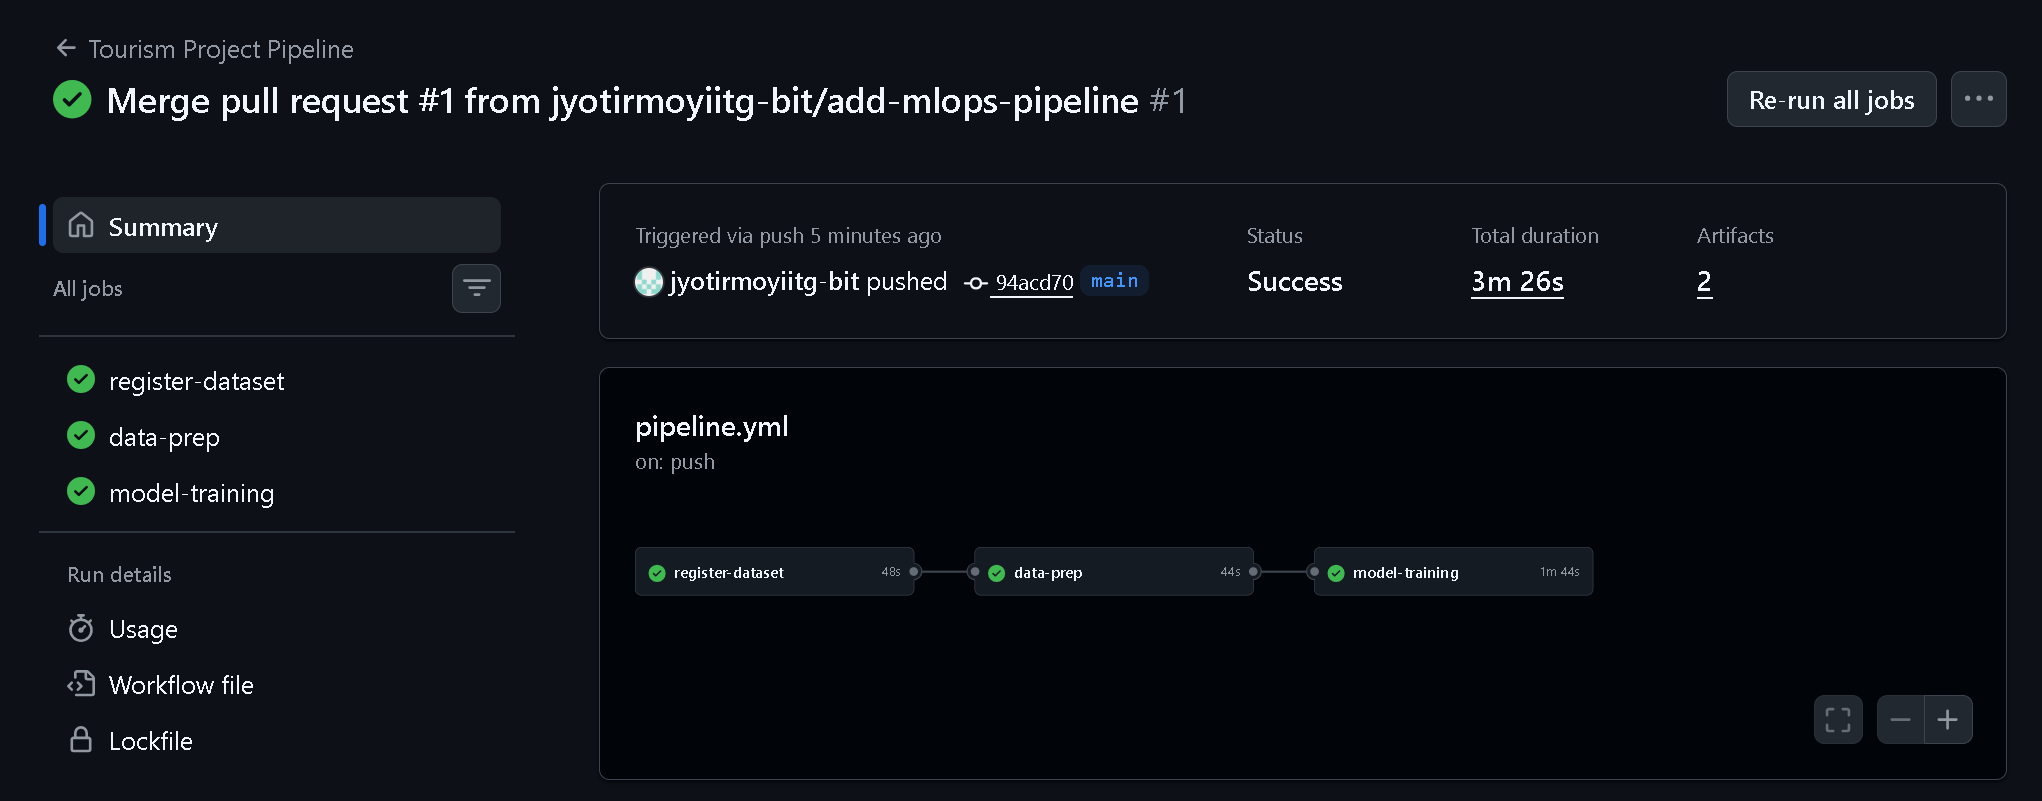

In [17]:
# Local project structure
skip = {".git", ".venv", "mlruns", "mlartifacts", "__pycache__", ".ipynb_checkpoints"}
for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in skip]
    depth = root.count(os.sep)
    print("  " * depth + os.path.basename(root) + "/")
    for f in files:
        if not f.endswith((".docx", ".html")) and depth > 0: print("  " * (depth + 1) + f)

./
  .github/
    workflows/
      pipeline.yml
  tourism_project/
    requirements.txt
    data/
      tourism.csv
    deployment/
      app.py
      best_tourism_model.joblib
      requirements.txt
    model_building/
      data_register.py
      prep.py
      train.py


### Streamlit Community Cloud
App: https://tourismpackage-mkmancg8d7uf6xtrueratt.streamlit.app/

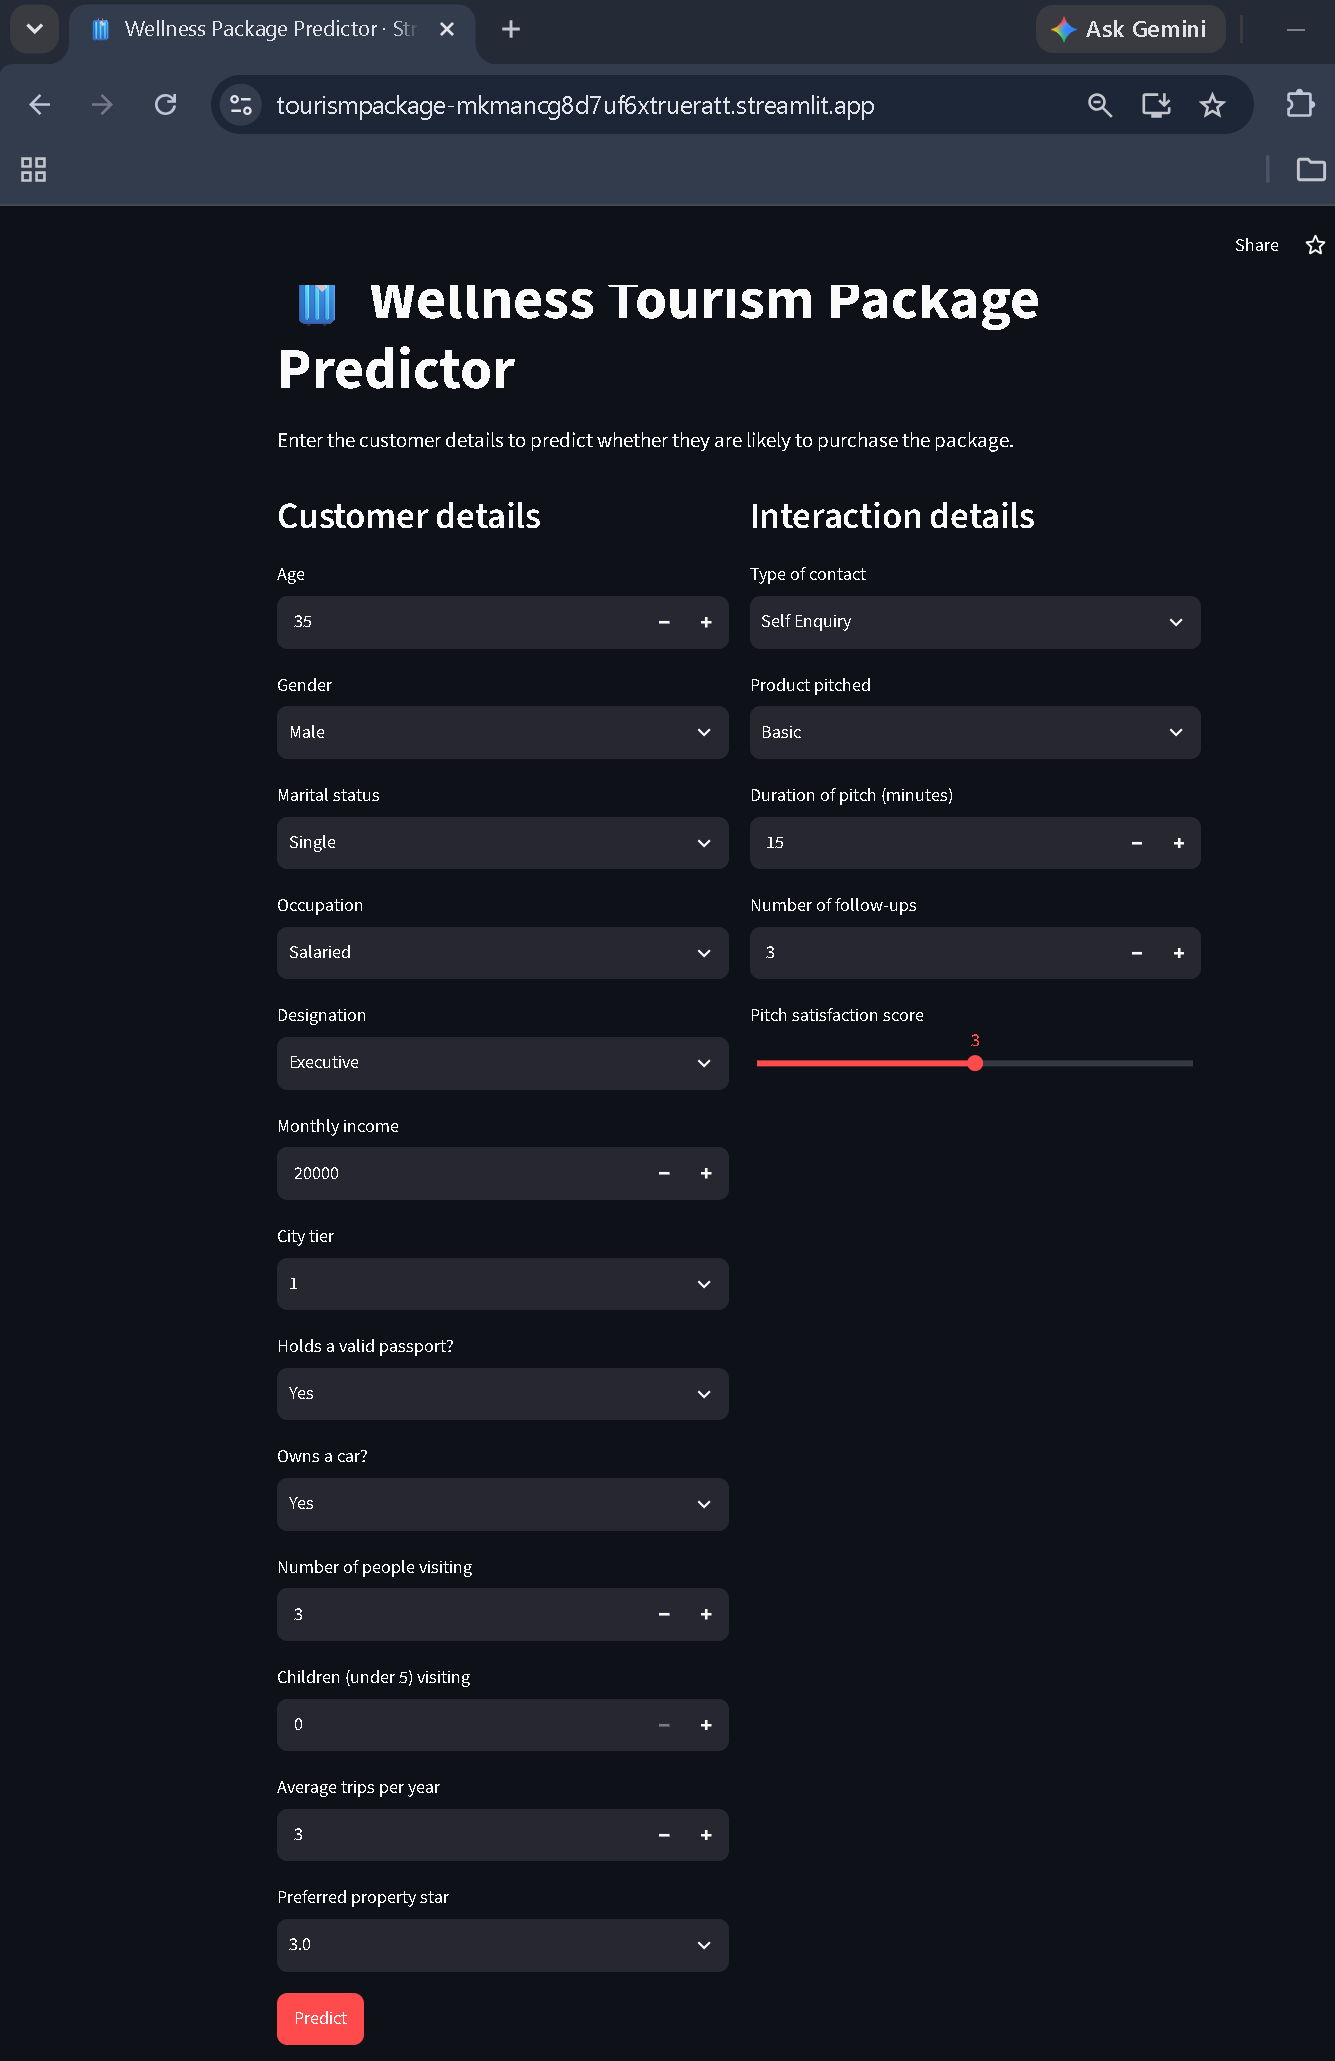

### Streamlit Community Cloud
App Testing Prediction: https://tourismpackage-mkmancg8d7uf6xtrueratt.streamlit.app/ 
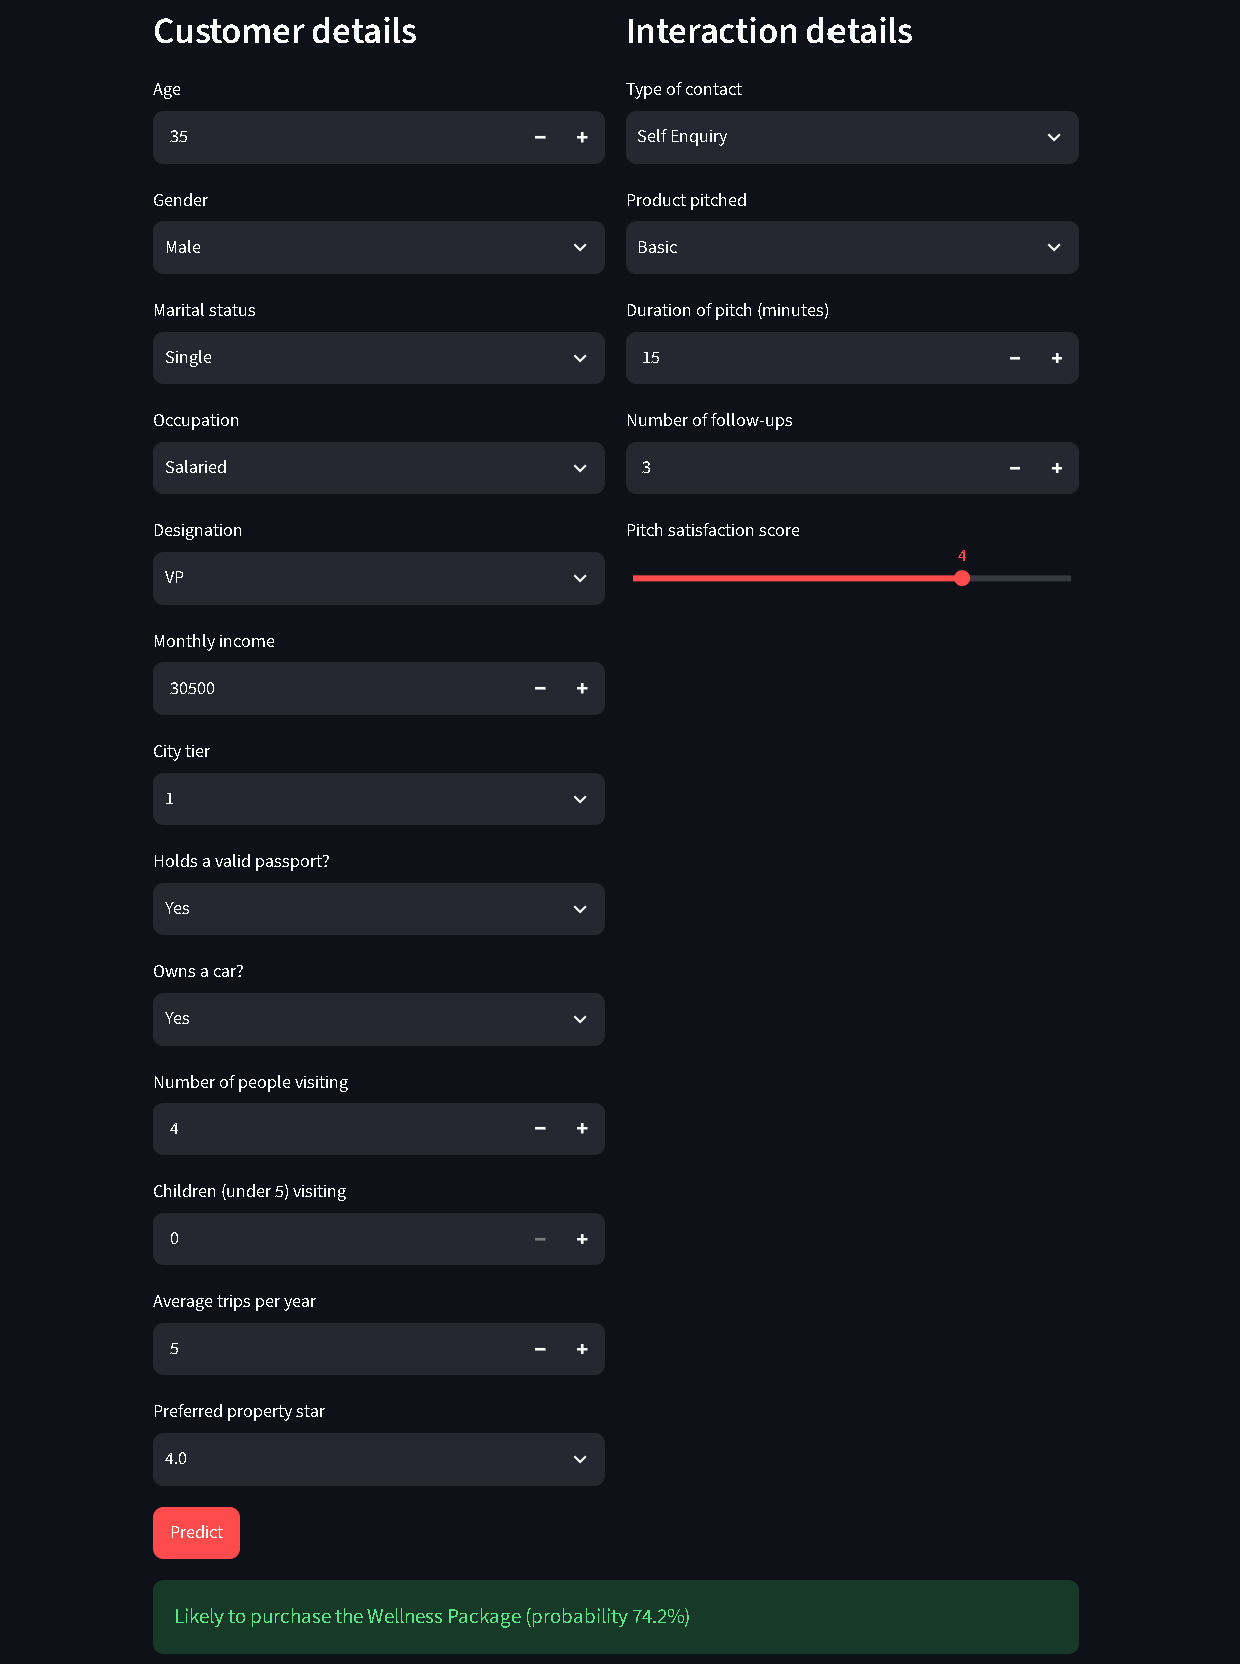

## 9. Summary and Insights
- **Automation:** a single push to `main` re-validates the data, rebuilds the splits, re-tunes and re-tracks the model, and commits the new model file; the Streamlit app picks it up from the repo - no manual steps.
- **Reproducibility:** pinned dependency versions in both requirements files, a fixed random seed, and the same scripts used locally and in CI.
- **Experiment tracking:** all 108 hyperparameter combinations and the final train/test metrics are logged in MLflow, making the choice of the best model auditable.
- **Model:** XGBoost with class-imbalance weighting and a 0.45 decision threshold gives ~0.85 test recall / 0.93 ROC-AUC, so the marketing team can prioritise likely buyers rather than calling everyone.
- **Business insight:** passport holders, customers pitched cheaper packages and junior designations convert most often - useful for targeting the Wellness package.
- **Limitations / next steps:** the model uses post-contact pitch features, so it is best viewed as a lead-prioritisation aid during the sales process; add data/model drift monitoring, a scheduled retraining trigger and automated tests (data validation, model-quality gate) to the pipeline.